# SQChip-EM 1-qubit template: a Quantcore-PDK rebuild, step by step

**Source:** Secbrain, *SQChip-EM*, the layout-to-EM dataset (DOI 10.5281/zenodo.20489133), from
`chip_code/metal_KDD_1qubit.py` (`LayoutParams`, `populate_design`) and `data/sqchip_em_1q/summary.csv`,
<https://github.com/Secbrain/SQChip-EM>. The repo states no licence; it is rebuilt regardless (decision, 2026-11-03), credited
here and distributed under the GPL. Spec: `docs/designs/community/sqchip_em.md`.

**What the chip is:** the 1-qubit Qiskit Metal template behind the dataset's 532 HFSS/Q3D rows:
- a `TransmonPocket` (pads 520 µm, pocket height 780 µm, readout pad 180 × 150 µm);
- an 8.5 mm λ/2 readout, capacitive at both ends;
- a `CapNInterdigitalTee` (12 fingers, 160 µm long, 1.2 µm gap) to a 5.5 mm feed meander from one launchpad.

In the dataset only the qubit position varies (L_J 12 nH, C_J 2 fF). At dx = dy = 0: f_q 4.734 GHz, f_r 6.099 GHz,
g/2π 200–294 MHz, κ/2π 5.3–6.1 MHz, C_in ≈ 52 fF.

**This notebook rebuilds the chip in the Quantcore PDK; it is not a replica.** What the rebuild keeps and what the PDK
changes:

| topic | source (SQChip-EM) | this rebuild |
|---|---|---|
| die and frame | 12 mm Metal canvas, mostly empty, no frame | PDK 7.5 mm die: dicing L's, alignment grids, device ID `SQCHIP-1Q` |
| stack | silicon (HFSS) | PDK sapphire 650 µm, εr 10.25 |
| qubit, tee, launchpad | Metal cells and options | the same cells through the `metal:` wrappers, same options |
| junction | lumped L_J 12 nH, C_J 2 fF | Quantcore Nb trilayer junction drawn for L_J = 12 nH (`trilayer_junction`); R_n is flagged, not retuned |
| readout and feed | Metal meanders, 8.5 mm λ/2 and 5.5 mm feed | qcc meanders of the same lengths |
| launchpad position | 2.4 mm west of the tee, well inside the canvas | **PDK pad rule**: slid west until its etch is `frame.pad_edge` = 100 µm from the die edge (same height) |
| placement | the canvas is centred on the qubit | **PDK**: the qubit, readout and tee are centred in the die |
| cheese | none (`GDS_DISABLE_CHEESE = True` in the source) | **PDK band** (`cheese: "auto"`): the original has none |
| netlist, LOM, FEM jobs | HFSS/Q3D rows | our netlist, LOM and Q3D / eigenmode job exports |

**Use:** a LOM cross-check against the dataset row. The dataset is silicon and HFSS, this is sapphire and LOM, so
expect f_r a few percent higher and g of the same order.

**How this notebook goes.** First the **Design**: the chip is laid out one segment at a time, each segment its own
cell with a picture of the chip so far — the die, the pocket transmon with its trilayer junction, the interdigital tee and the λ/2
readout, the centring of that core, the launchpad on the PDK pad rule, the feed meander, and then the whole chip (the
sim group and targets, the save). The order is the geometry's: the tee is placed from the qubit's readout pin, and the
launchpad from the tee's feed port after the centring. Then the same steps as the Flow strip of the Quantcore
KLayout plugin: **Check** (DRC, netlist) → **LOM** (simulation and plots) → **Simulate** (export to HFSS, the
component simulation, the eigenmode simulation, the full-wave run) → **Results** (plots, the values, FEM against the
LOM, a feedback step and the iteration to a target) → **Fab**.

**Nothing here solves on its own.** The switches (the code cell after Setup) are off (`RUN_FEM = False`): FEM results
are loaded when a solve has been kept, otherwise each FEM cell says what would appear. The notebook before this
rewrite (the layout in a few cells, with its outputs) is kept as `sqchip_em.v1.ipynb`; both save the same
`sqchip_em.json`.

## Setup

The notebook runs from the repository root. `_common` holds the table, snapshot and PDK helpers shared by the design
notebooks. `LIVE` follows `QCC_LIVE`: with KLayout open, every change below shows up live; with `QCC_LIVE=0` (tests,
batch runs) the snapshots are rendered headless.

**The switches** (next cell): `RUN_FEM` solves the FEM jobs in AEDT 2024 R1 or newer, one after the other (a new
non-graphical AEDT unless `AEDT_MODE` says otherwise; an AEDT you have open is never touched); `RESOLVE` solves again
even when kept results match; `FEM_FAST` exports with the library's fast test settings (minutes, values not
converged); `MAX_ITER` caps the feedback iterations towards the targets.

In [2]:
%config InlineBackend.figure_formats = ["png"]
import os, sys
from pathlib import Path
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "pyproject.toml").exists())
os.chdir(ROOT)                                   # paths below are relative to the repo root
sys.path.insert(0, str(ROOT / "examples" / "designs"))
from _common import *                            # tables, snapshots, PDK helpers
from quantcore_circuits.designer import Designer
from quantcore_circuits.layouts.registry import trilayer_junction
from quantcore_circuits.circuit.bridges import rn_from_lj

LIVE = os.environ.get("QCC_LIVE", "1") == "1"   # live KLayout by default; QCC_LIVE=0 for batch runs
OUT = Path("examples/designs/community")
OUT.mkdir(parents=True, exist_ok=True)

In [3]:
RUN_FEM = False        # True (or a set such as {"q3d_cmatrix"}): solve the FEM jobs in AEDT 2024 R1+, one at a time
RESOLVE = False        # True (or a set of analyses): solve again even when kept results match
FEM_FAST = True        # True: the library's fast test settings (minutes, not converged); False: the settings as written
AEDT_MODE = "batch"    # "batch" (no window) | "gui" (a new AEDT window, left open) | "attach" (the AEDT you have open)
MAX_ITER = 3           # feedback iterations towards the targets (Results 5)

## The Quantcore PDK this chip uses

The PDK facts this chip relies on. Every rule below is applied by the library, not by this notebook: the frame and
the cheese are drawn by the chip build, the pad rule by `edge=`, the junction by `trilayer_junction`, and the PDK
design warnings come out of the DRC.

In [4]:
display(Markdown(pdk_facts_md()))

| PDK rule | value |
|---|---|
| process | `quantcore_nb_sapphire_v1` v3 |
| stack | sapphire 650 µm, εr 10.25, Nb film (λ_L 0.09 µm) |
| CPW default | centre 10 µm, gap 6 µm, bend radius 100 µm |
| die frame | standard die 7.5 × 7.5 mm; L dicing markers (1000/0, 25 µm wide), 3 × 3 alignment grids (1001/0) in 500 µm corner areas, boundary 100/0, device ID |
| pad rule | bond pads / launchers: outer etch edge **100 µm** (`frame.pad_edge`) from the die edge (`edge="auto"`) |
| junctions | Nb/AlOx/Nb trilayer, Nb Δ 1.4 meV, R_n 40–50 kΩ (nominal 45 kΩ = 0.5 × 0.6 µm), C_J 50 fF/µm²; fingers 2/0 + 4/0, spacer 50/0 (+ 51–53/0 dose gradient) |
| qubit band | f_q 4–8 GHz (outside: DRC design warning `pdk_fq`) |
| cheese | the original design's own if it has one, else the PDK band: 5 µm squares, 20 µm gaps, 3 rows around the 3/0 keep-outs (chip param `cheese`: auto / pdk / original) |
| 3/0 keep-out | filled second-metal etch: routes CPW footprint + 10 µm, components etch bbox + 24 µm (or the cell's own) |
| corner rounding | fab only: r = 0.25 × the shortest dimension, ≤ 10 µm |

# Design: the layout, one segment at a time

The chip is built the way a designer would lay it out by hand: the die, the bond pads, the readout, the qubits, the
coupling, the control lines, and then the whole chip. Each segment is one cell with one picture of the chip so far
(and, live, KLayout redraws after every cell). **The order here is fixed by the geometry** (it is the source's): the tee sits 1.0 mm east and 2.0 mm north
of the qubit's readout pin, so it follows the qubit; the core is centred before the launchpad exists, because the pad
is pinned to the die edge and would drag the centring; the pad takes its height from the tee's feed port after that
shift, so the pad and its feed come last.

| segment | what is placed here |
|---|---|
| 1 | the PDK's standard 7.5 mm die with its frame |
| 2 | qubit placement: the trilayer junction and the `TransmonPocket` at the die centre |
| 3 | the readout: the interdigital tee (from the qubit's readout pin) and the 8.5 mm λ/2 to it |
| 4 | the PDK placement: the core (qubit, readout, tee) centred in the die |
| 5 | the bond pad: the launchpad at the tee's height, slid to the west edge by the PDK pad rule |
| 6 | the readout feed: the 5.5 mm meander from the launchpad to the tee |
| 7 | coupling and control lines: none (one qubit, no drive line) |
| 8 | the whole chip: the sim group and the dataset's targets, the save |

## Design 1 · The die and its frame

`Designer(name, box=...)` opens an empty chip. The box is the die (µm); the PDK draws its frame round it: the L dicing
markers in the corners (layer 1000/0), the 3 × 3 alignment grids (1001/0), the chip boundary (100/0) and the device ID
(`name_chip`) on a free edge. The source's 12 mm canvas is mostly empty, so the rebuild uses the PDK's standard
7.5 mm die.

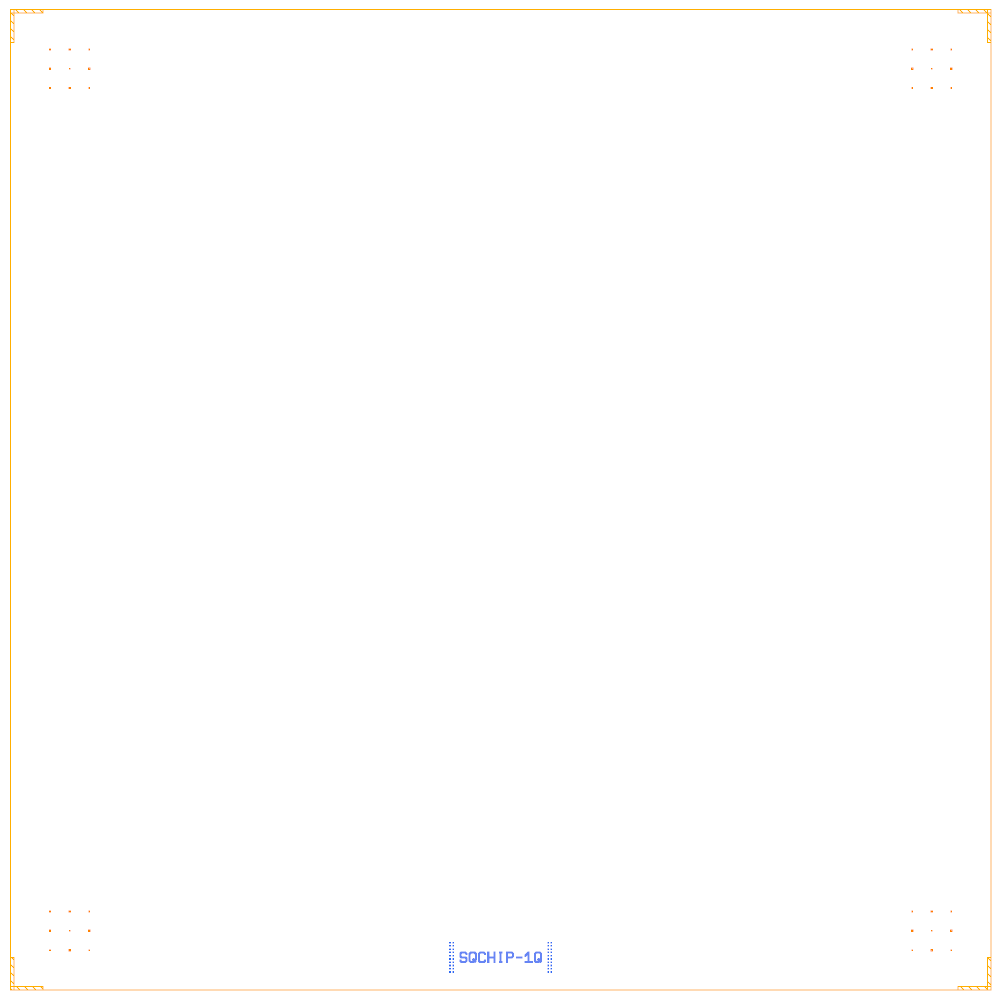

**On the chip so far:** 0 pads · 0 qubits · 0 other components · 0 routes · 0 declared couplings. **This step added** nothing new to the layout.

WindowsPath('examples/designs/community/sqchip_em_die.png')

In [5]:
d = Designer("sqchip_em", box=(0, 0, 7500, 7500), chip={"name_chip": "SQCHIP-1Q"}, live=LIVE)
layout_step(d, OUT / "sqchip_em_die.png", size=(1000, 1000), width=360)

## Design 2 · Qubit placement: the pocket transmon and its junction

**The junction.** The dataset fixes L_J = 12 nH. `trilayer_junction(cell, lj_nH=12)` returns two things:
- the cell parameters that draw a Quantcore Nb/AlOx/Nb trilayer junction (fingers on 2/0 and 4/0, spacer 50/0 with the
  51–53/0 dose gradient) sized for that L_J on the PDK junction rule;
- the junction values the LOM uses (L_J and C_J of the drawn junction).

At 12 nH the junction is small, so R_n ≈ 80 kΩ, **outside the PDK window of 40–50 kΩ**. Following the project rule
(values are flagged, never retuned), the dataset's L_J stays and the DRC reports it as the design warning `pdk_rn`.

In [6]:
LJ_NH = 12.0                                     # the dataset's Lj (every 1q row)
JJP, JJ = trilayer_junction("metal:TransmonPocket", lj_nH=LJ_NH)
print("cell parameters:", JJP)
print("LOM junction:   ", JJ, f"→ R_n {rn_from_lj(JJ['Lj_nH']) / 1e3:.1f} kΩ (PDK window 40–50 kΩ)")

cell parameters: {'junction_type': 'Quantcore Junction', 'junction_params': {'lj_nH': 12.0}}
LOM junction:    {'Lj_nH': 12.0258, 'Cj_fF': 8.4} → R_n 80.4 kΩ (PDK window 40–50 kΩ)


**The qubit.** The source's `LayoutParams` give the pocket: 520 µm pads in a 780 µm pocket, with one readout
connection pad (180 × 150 µm, 1.4 µm gap) at the top right. The Metal cell is used through the `metal:` wrapper, so its
options and pins are Metal's; `q.readout` is the readout pad's pin.

<metal:TransmonPocket Q1 ports=['readout', 'squid_a', 'squid_b']>
readout pin: (4175.0, 3931.4)


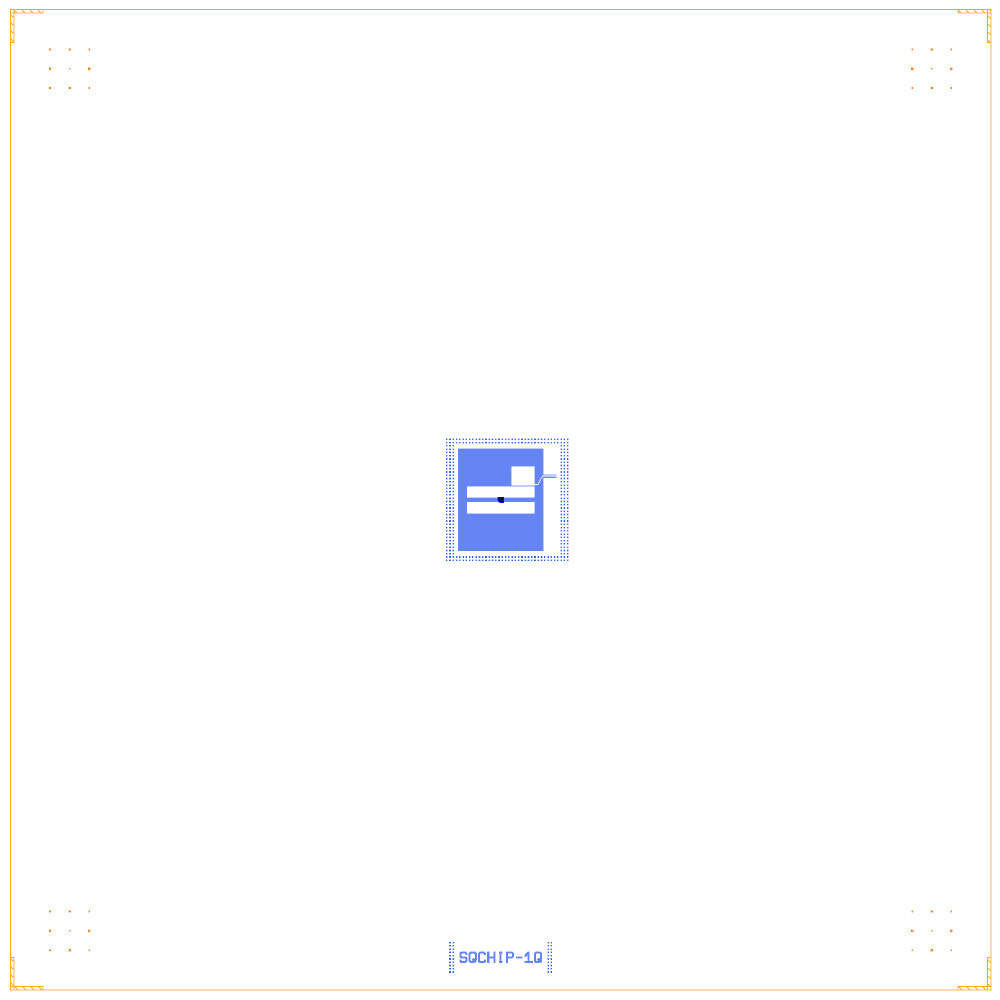

**On the chip so far:** 0 pads · 1 qubits · 0 other components · 0 routes · 0 declared couplings. **This step added** 1 component(s) `Q1`.

WindowsPath('examples/designs/community/sqchip_em_s2_qubit.png')

In [7]:
POCKET = dict(pad_width=520, pocket_height=780,   # LayoutParams; readout pad = the dataset rows' 180 × 150, gap 1.4
              connection_pads={"readout": dict(loc_W=+1, loc_H=+1, pad_width=180, pad_height=150, pad_gap=1.4)})
X0 = Y0 = 3750.0                                 # the source's canvas is centred on Q1 (dataset row dx = dy = 0)
q = d.add("Q1", "metal:TransmonPocket", at=(X0, Y0), junction=JJ, **POCKET, **JJP)
print(q)
print("readout pin:", port_xy(d, "Q1.readout"))
layout_step(d, OUT / "sqchip_em_s2_qubit.png", size=(1000, 1000), width=360)

## Design 3 · Readout: the interdigital tee and the λ/2

**The interdigital tee.** The dataset's tee (12 fingers, 160 µm long, 1.2 µm gap) joins the feed (`prime_start`) to the
readout (`second_end`). The source puts it at the readout pin + (1.0, 2.0) mm. Its `prime_end` stays open, as in the
source. It is placed from the
qubit's pin (`port_xy`), so it follows the qubit.

In [8]:
TEE = dict(prime_width=14, prime_gap=6, second_width=10, second_gap=6, cap_gap=1.2, cap_width=8,
           finger_length=160, finger_count=12, cap_distance=220)      # dataset tee: fl160, fc12, cg1.2
rx, ry = port_xy(d, "Q1.readout")                # Metal: pins["readout"]["middle"]
tee = d.add("RO_TEE", "metal:CapNInterdigitalTee", at=(rx + 1000, ry + 2000), **TEE)
print(tee)

<metal:CapNInterdigitalTee RO_TEE ports=['prime_end', 'prime_start', 'second_end']>


`d.route(name, from_port, to_port, meander=L)` draws a CPW (PDK default 10/6 µm unless given) of total length `L`
between two ports; the router adds the meander. The readout is the source's 8.5 mm λ/2 between the tee's second end
and the qubit's readout pad, with 6 meanders and 25 µm bends (Metal's spacing 280 µm): one KQC
`Meander` with the 6 turns asked for (fewer, with a warning, only if 6 would be narrower than the bend radius).

RO_RES drawn length: 8500.0 µm


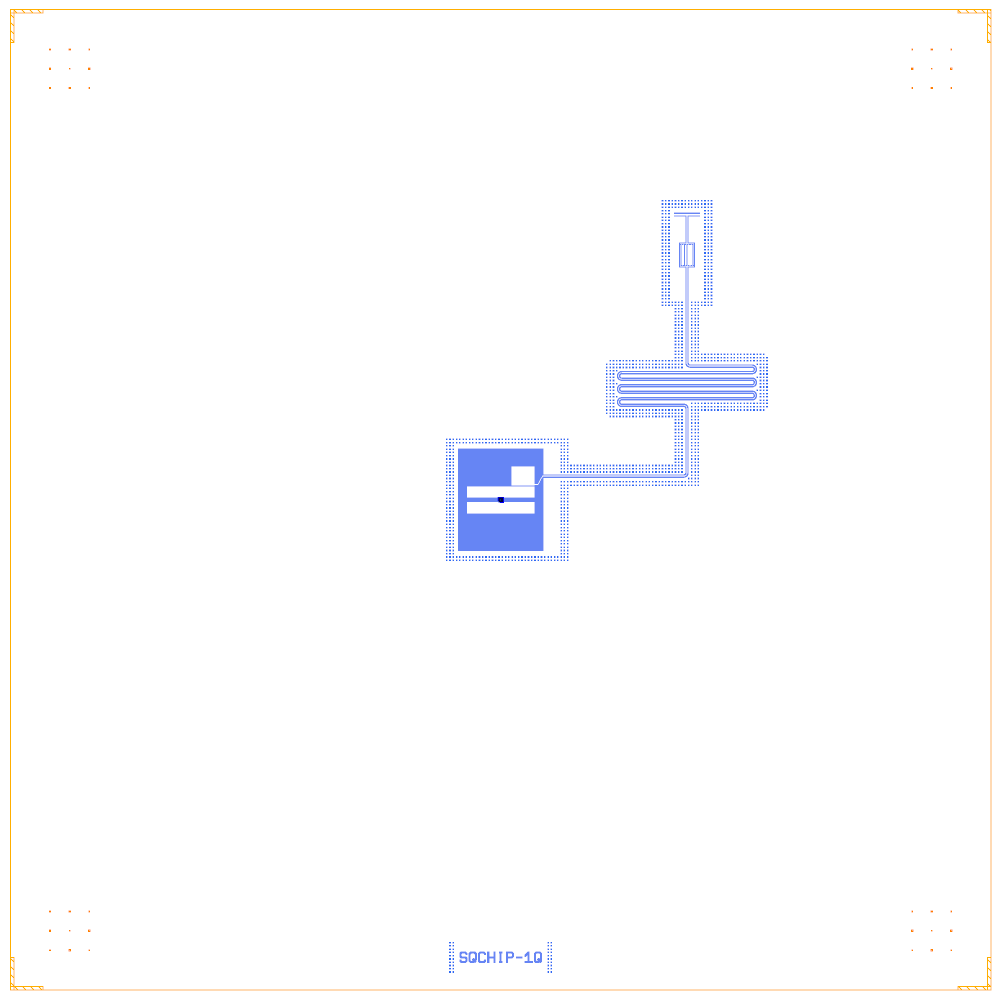

**On the chip so far:** 0 pads · 1 qubits · 1 other components · 1 routes · 0 declared couplings. **This step added** 1 component(s) `RO_TEE` and 1 route(s) `RO_RES`.

WindowsPath('examples/designs/community/sqchip_em_s3_readout.png')

In [9]:
ro = d.route("RO_RES", tee.second_end, q.readout, meander=8500, r=25).set(meanders=6)   # λ/2, capacitive at both ends
rebuild(d)
print(f"RO_RES drawn length: {ro.length:.1f} µm")
layout_step(d, OUT / "sqchip_em_s3_readout.png", size=(1000, 1000), width=360)

## Design 4 · PDK placement: centre the core, before the pad

The PDK wants the chip content in the middle of the die. `center_in_die(d)` measures the bounding box
of every instance and route and shifts them all (instance positions, route waypoints) so that box is centred. The
qubit, the readout and the tee are centred here, before the launchpad is added: the launchpad is pinned to the die
edge by the pad rule, so it cannot take part in the centring. From the v1 run: the
core moves by (−598, −902) µm.

shift applied (µm): (-598.0, -902.2)
Q1 now at (3152.0, 2847.8)


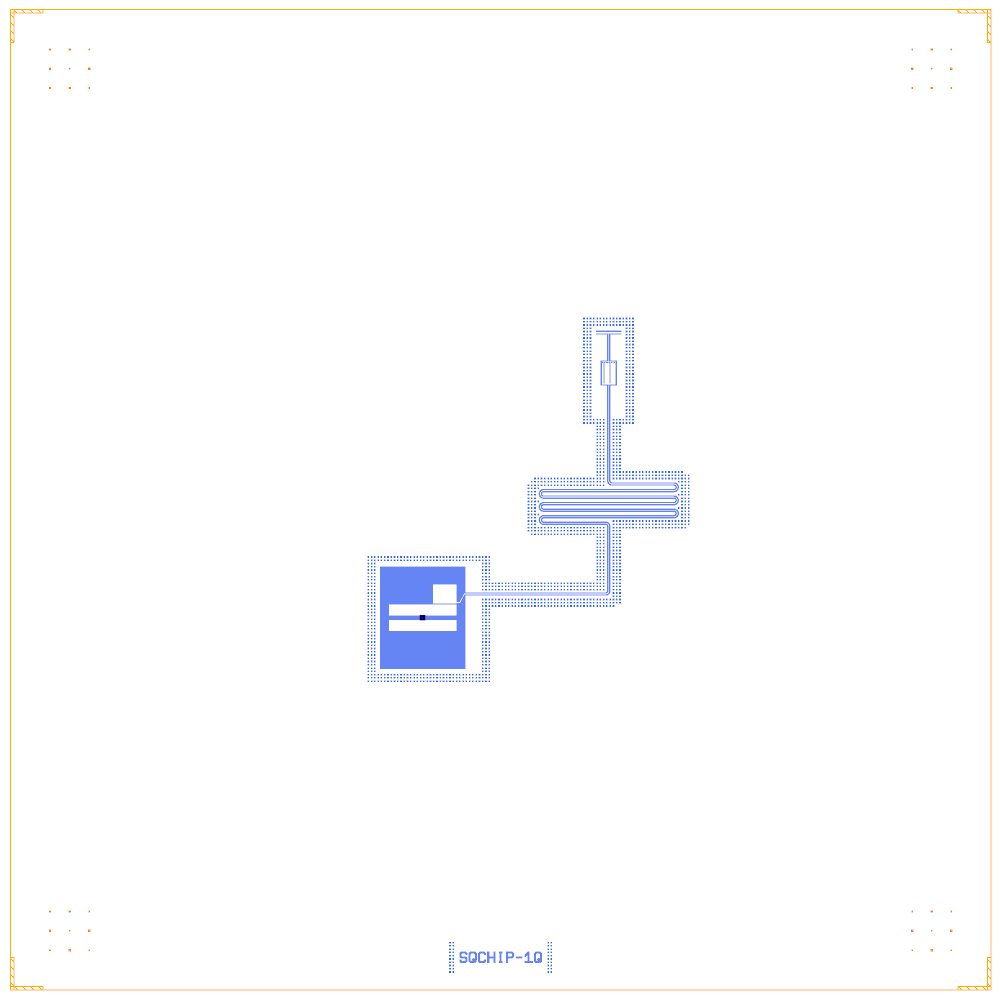

**On the chip so far:** 0 pads · 1 qubits · 1 other components · 1 routes · 0 declared couplings. **This step added** nothing new to the layout.

WindowsPath('examples/designs/community/sqchip_em_s4_centred.png')

In [10]:
shift = center_in_die(d)
print("shift applied (µm):", shift)
qx, qy = d.data["instances"]["Q1"]["place"]["at"]
print("Q1 now at", (qx, qy))
layout_step(d, OUT / "sqchip_em_s4_centred.png", size=(1000, 1000), width=360)

## Design 5 · Bond pad: the launchpad and the PDK pad rule

**The pad rule.** The source's launchpad sits 2.4 mm west of the tee, at the tee's height. The PDK puts every bond pad
and launcher with the outer edge of its etch **`frame.pad_edge` = 100 µm from the die edge**. `edge="w"` slides
the pad perpendicular to the west edge until that holds; its position along the edge (y) is kept. `pads_md(d)` lists
each pad's distance to the nearest edge. It is added only
now: its height is the tee's feed port after the centring (Design 4).

| pad | cell / launcher | nearest die edge | outer etch → die edge (µm) | PDK rule |
|---|---|---|---|---|
| LP_RO | `metal:LaunchpadWirebond` | w | 100.0 | ✓ |

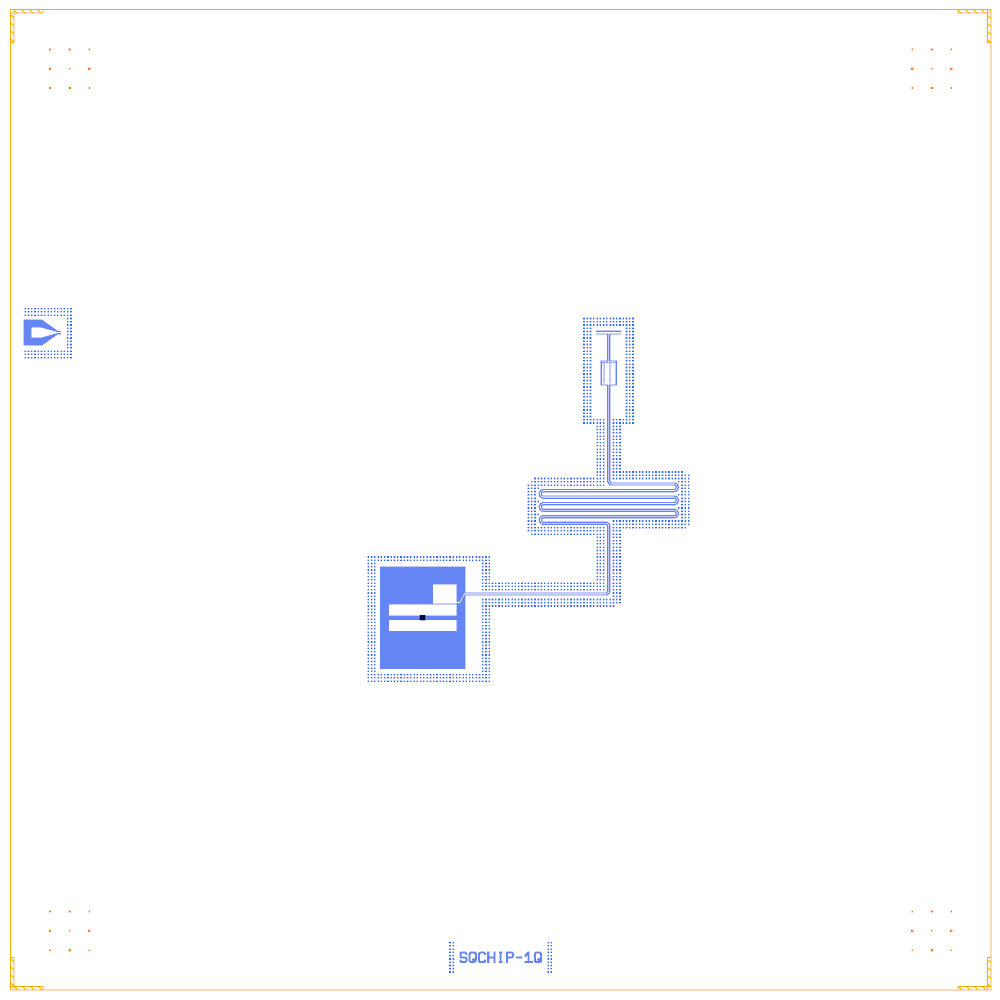

**On the chip so far:** 1 pads · 1 qubits · 1 other components · 1 routes · 0 declared couplings. **This step added** 1 component(s) `LP_RO`.

WindowsPath('examples/designs/community/sqchip_em_s5_pad.png')

In [11]:
tx, ty = port_xy(d, "RO_TEE.prime_start")
lp = d.add("LP_RO", "metal:LaunchpadWirebond", at=(tx - 2400, ty), edge="w", trace_width=10, trace_gap=6)
rebuild(d)
display(Markdown(pads_md(d)))
layout_step(d, OUT / "sqchip_em_s5_pad.png", size=(1000, 1000), width=360)

## Design 6 · Readout: the feed

**The feed.** The source's 5.5 mm feed meander runs from the launchpad's `tie` to the tee's `prime_start`. Its length
is kept; with the launchpad now at the die edge it needs fewer meanders.

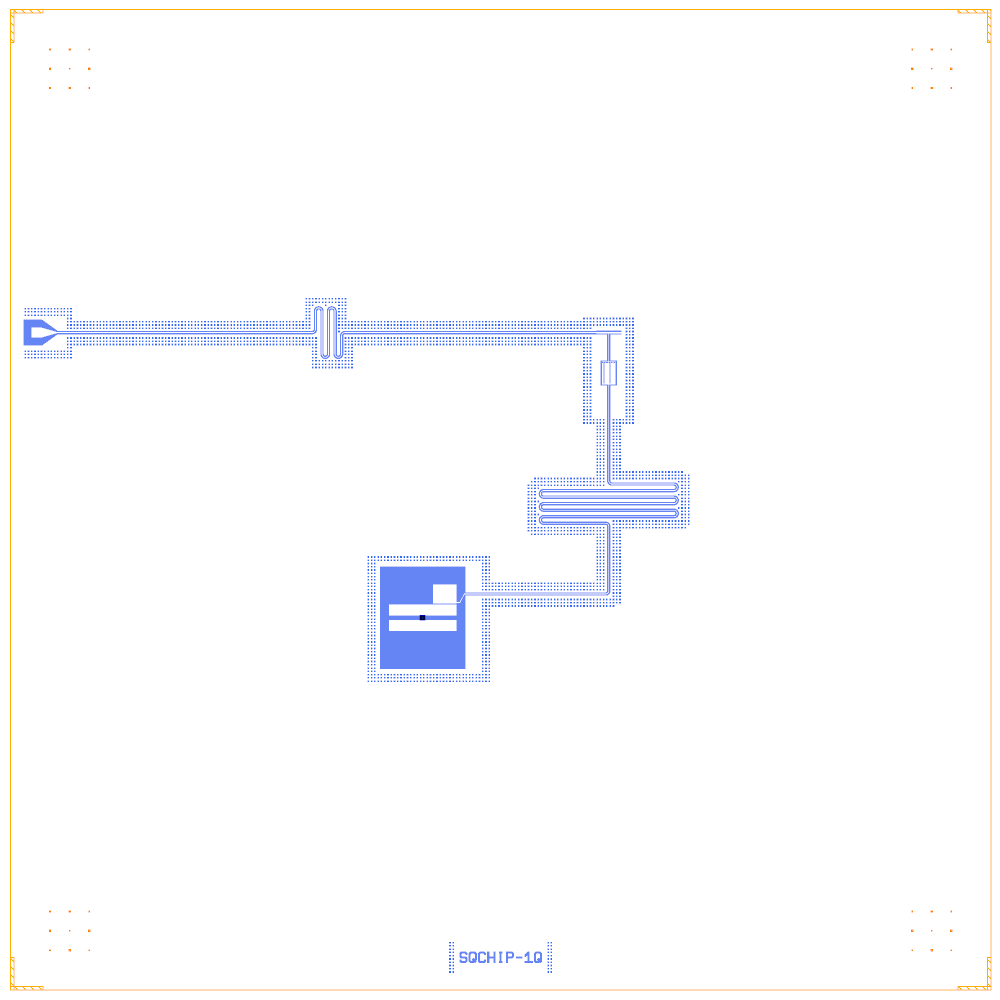

**On the chip so far:** 1 pads · 1 qubits · 1 other components · 2 routes · 0 declared couplings. **This step added** 1 route(s) `RO_FEED`.

WindowsPath('examples/designs/community/sqchip_em_s6_feed.png')

In [12]:
feed = d.route("RO_FEED", lp.tie, tee.prime_start, meander=5500, r=25).set(meanders=4)
rebuild(d)
layout_step(d, OUT / "sqchip_em_s6_feed.png", size=(1000, 1000), width=360)

## Design 7 · Coupling and control lines: none

One qubit: nothing to couple to, and the source draws no drive or flux line (its 1-qubit template has the readout
only). Nothing is placed here.

## Design 8 · The whole chip: sim group, targets, save

**Sim group and targets:** one sim group holds the qubit, the readout and the tee (a Q3D C-matrix and an eigenmode /
EPR job); the targets are the dataset row at dx = dy = 0 (f_q 4.734 GHz, f_r 6.099 GHz). The content was centred in
Design 4.

**Save.** The JSON is the deliverable. `save_design` writes it and compares it with the file it replaces (the
previous run's, the `.v1` notebook's): the segments above changed how the chip is built, not the chip, so it should say
*same design*. The file keeps the previous key order (here every instance and route comes in the v1's order), so `git diff` stays empty.

**Same design as before:** `examples/designs/community/sqchip_em.json` is identical to the file it replaces (byte for byte). The segments changed how the chip is built, not the chip.

<Designer sqchip_em: 3 instances, 2 routes, live=False> → examples\designs\community\sqchip_em.json
{'RO_RES': 8500.0, 'RO_FEED': 5500.0}


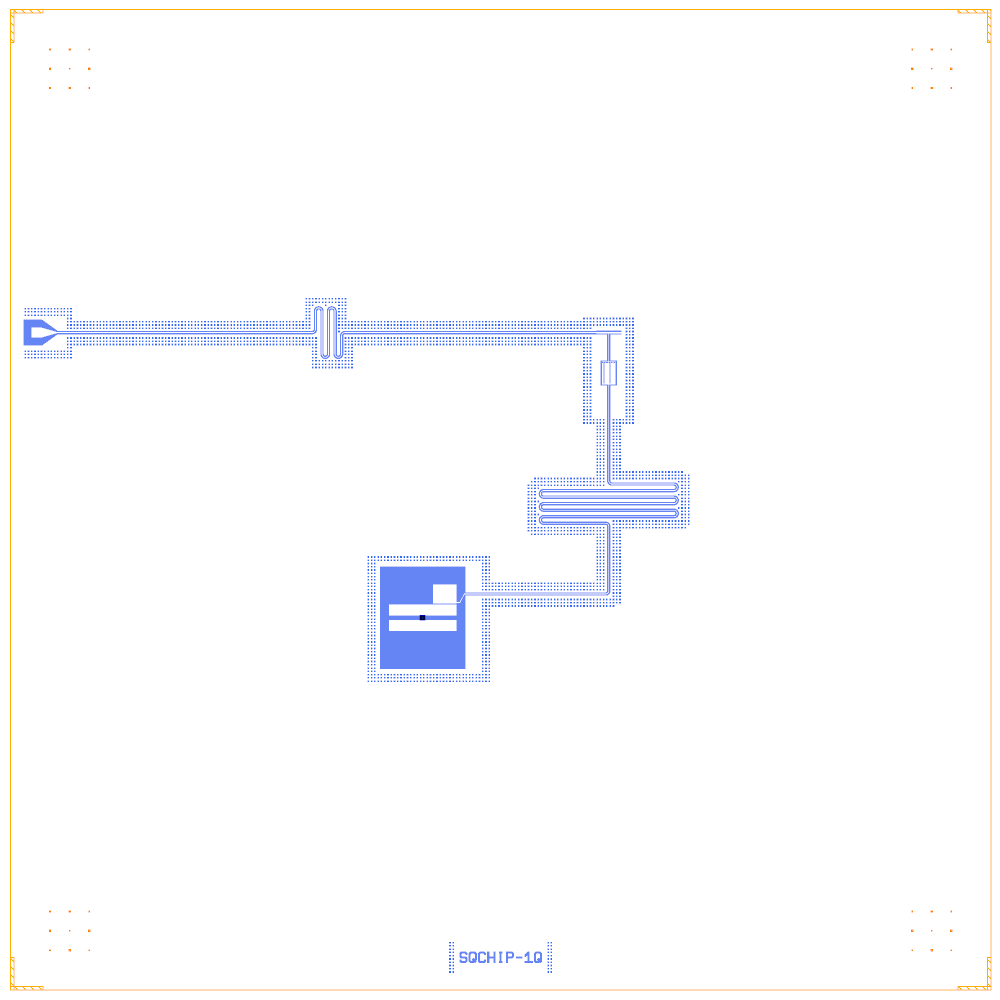

**On the chip so far:** 1 pads · 1 qubits · 1 other components · 2 routes · 0 declared couplings. **This step added** nothing new to the layout.

WindowsPath('examples/designs/community/sqchip_em_routes.png')

In [13]:
d.sim_group("Q1R", ["Q1", "RO_RES", "RO_TEE"])                                   # FEM: qubit + readout + tee
d.targets(Q1={"f_q_GHz": 4.734}, RO_RES={"f_GHz": 6.099})                         # dataset row dx = dy = 0
rebuild(d)
DESIGN, same = save_design(d, OUT / "sqchip_em.json")
display(Markdown(same))
print(d, "→", DESIGN)
print({k: round(v, 1) for k, v in d.result.route_lengths().items()})
layout_step(d, OUT / "sqchip_em_routes.png", size=(1000, 1000), width=360)

# Check: DRC and netlist

The plugin's *Check* step: the design rules, then the lumped circuit the layout turns into.

## Check 1 · DRC

`d.drc()` checks connectivity (dangling ports, overlaps, route crossings, netlist opens and shorts) and the PDK
margins. There are three kinds of finding:
- **errors** would make the chip wrong (a short, a route through a component); there must be none;
- **warnings** are worth a look but can be intended: here the junction attachment points (`squid_a` / `squid_b`, the
  cell draws its own junction) and the tee's open `prime_end`, as in the source;
- **PDK design warnings** flag values outside the PDK margins (`pdk_rn`, `pdk_fq`, `pad_edge`, `pdk_claw`); they are
  reported, never enforced.

Expected (from the v1 run): **no errors**; 3 `dangling_port` warnings (`squid_a`, `squid_b` and the tee's open `prime_end`);
one `pdk_rn` (R_n 80.4 kΩ). No `pad_edge`: the launchpad sits at 100 µm.

`pdk_report(d)` sums up the PDK checks: cheese source, centring, junction types, design warnings.

In [ ]:
rebuild(d)
rep = d.drc()
display(Markdown(drc_md(rep)))
display(Markdown(pdk_report(d)))

The content centre is west of the die centre because the launchpad is pinned to the west edge; the qubit, readout and
tee themselves are centred (Design 4); in the v1 run: (−1364, +42) µm, the launchpad and the 5.5 mm feed pulling it west. The one design warning is the 80 kΩ junction (dataset L_J kept).

## Check 2 · Netlist

`d.lom()` turns the layout into a lumped circuit: every component's LOM model maps its ports to circuit nodes, and
every route becomes a wire, a resonator or a coupling. Here:
- the floating pocket transmon: two pad nodes (`Q1.island1`, `Q1.island2`) and the trilayer junction between them;
- the readout pad's coupling capacitance to the near pad;
- the λ/2 readout `TLres` between the qubit pad and the tee's second end;
- the IDC between the tee's coupled node and the feed node;
- one 50 Ω port at the launchpad.

In [ ]:
lb = d.lom()
show_netlist(lb)
print(lom_summary(lb))

# LOM: simulate the lumped circuit, and plot it

## LOM 1 · The LOM simulation vs the dataset row (dx = dy = 0)

`simulate_groups` builds a QuCat network from the netlist (normal modes, κ, participations) and diagonalises the
circuit Hamiltonian in QuTiP (dressed f_q, α, f_r, χ). Targets are in brackets. The dataset gives f_q 4.734 GHz and
f_r 6.099 GHz on silicon (HFSS); on sapphire with LOM estimates, expect f_r a little higher and a large χ (g is
≈ 0.2–0.3 GHz in the dataset).

What the tables show (from the v1 run): f_q **5.118 GHz** (+8 % on the dataset's 4.734: the drawn trilayer junction is
12.03 nH with C_J 8.4 fF and the LOM pocket estimate differs from HFSS), α −301 MHz; f_r **6.1245 GHz** (+0.4 %);
χ −8.37 MHz. κ is **93.4 MHz**, far above the dataset's 5.3–6.1 MHz: the LOM estimate of an IDC with 1.2 µm
gaps is too large (a request to the LOM owner); a Q3D run of the tee fixes it (Simulate 2, Results 3).

In [ ]:
GROUP = ["Q1", "RO_RES", "RO_TEE", "RO_FEED", "LP_RO"]
res = simulate_groups(d, {"Q1R": GROUP}, max_modes=2)
display(Markdown(modes_md(res["Q1R"]) + "\n\n" + groups_md(res, d.data["targets"])))

## LOM 2 · The LOM in two plots

The same results as pictures: (a) the normal modes of the qubit + readout group (QuCat; the circle is the qubit, the
square the λ/2; filled markers are the QuTiP dressed values; red bars the dataset's values), (b) the readout's
dispersive shift |χ|. From the v1 run the readout sits on its red bar (+0.4 %) and the qubit 8 % above its own.

In [ ]:
plot_lom(res, OUT / "sqchip_em_lom.png", targets=d.data["targets"], title="sqchip_em: LOM vs the dataset row")

## LOM 3 · One geometry change, by hand

Before the FEM, a design step by hand. The LOM is cheap, so a design change can be checked in seconds. Here the tee's finger count goes from 12 to 6: the IDC
capacitance roughly halves, so the readout's κ (through the tee, κ ∝ C²) drops about threefold, and the readout moves
up because the IDC no longer loads its open end as much. From the v1 run: κ 93.4 → 28.7 MHz, f_r 6.1245 → 6.4532 GHz,
χ −8.37 → −6.21 MHz; f_q stays at 5.12 GHz. `design_copy` opens a second, non-live Designer
on the saved design, so the design file stays as it is.

In [ ]:
d2 = design_copy(DESIGN)
d2["RO_TEE"].set(finger_count=6)
res2 = simulate_groups(d2, {"Q1R": GROUP}, max_modes=2)
display(Markdown(params_delta_md(res, res2)))

> **Simulation PC (32 GB+ RAM).** The cells below solve FEM jobs in AEDT. On this notebook's chip they need the
> simulation PC: set `RUN_FEM = True` and `FEM_FAST = False` there, run them one job at a time, and keep the results
> (`fem/`). On a smaller PC leave `RUN_FEM = False`: the cells export the jobs and load kept results only.

# Simulate: export to HFSS, the component and eigenmode simulations, the full-wave run

The plugin's *Simulate* step. The LOM above uses analytic capacitance estimates; a finite-element job measures them.
Each job is a sim group cut out of the chip, written to `build/jobs/<design>_<group>_<analysis>/`. With
`RUN_FEM = False` (the default) the jobs are only exported: the cells load results that were solved and kept before
(in `examples/designs/community/fem/<job>/`), and otherwise say what would appear.

## Simulate 1 · Export to HFSS

The sim group `Q1R` (qubit, readout, tee) is exported as two jobs: a Q3D C-matrix job (capacitances by net name) and
an eigenmode/EPR job. The job folders are self-contained (`build/jobs/<design>_<group>_<analysis>`); exporting again
replaces a folder, results included. Simulation exports never carry cheese.

`RUN_FEM = False` only exports, and the next cells load results kept from an earlier solve. `FEM_FAST` (a switch at the top) picks the fast test settings for every job exported from here on. With
`RUN_FEM = True` the next cells solve each Ansys job in a **new batch, non-graphical** AEDT 2024 R1 (or newer), so an
AEDT window you have open is never touched. On another
machine: `qcc hfss solve build/jobs/<job>`.

In [ ]:
FEM_FAST = fem_fast(FEM_FAST)                    # the switch from the top: fast test settings, or as written
KEEP = fem_keep_dir(DESIGN)                      # examples/designs/community/fem/: solved results are kept here
jobs = export_sims(DESIGN, ["Q1R"], analysis="q3d_cmatrix")
jobs_eig = export_sims(DESIGN, ["Q1R"], analysis="eigenmode_epr")
display(Markdown(jobs_md(jobs) + "\n" + jobs_md(jobs_eig).split("\n", 2)[2]))

## Simulate 2 · Component simulation: the Q3D C-matrix

The capacitance of `Q1R`: the pocket's two pads, the readout pad, the λ/2, the tee's fingers and the feed the box
cuts, as named nets (`Q1.island1`, `Q1.island2`, the tee and readout nets). Each net is named after its LOM node, so
the matrix goes straight into the circuit (Results 3) — in particular the IDC's capacitance, which the LOM
over-estimates (LOM 1: κ 93 MHz from the v1 run against the dataset's ≈ 5.7 MHz). `fem_stage` solves the job with
`RUN_FEM`, else loads its kept results, else says that there are none.

In [ ]:
keep_q3d = fem_stage(jobs, RUN_FEM, KEEP, force=RESOLVE, aedt=AEDT_MODE)
display(Markdown(convergence_md({f"{g} · q3d": k for g, k in keep_q3d.items()})))
for g, k in keep_q3d.items():
    if k:
        display(Markdown(cmatrix_md(k)))

## Simulate 3 · Eigenmode simulation

The same box in HFSS eigenmode — the dataset's own kind of row: the junction is a lumped L_J ‖ C_J sheet, the feed
the box cuts ends in 50 Ω, so each mode's Q gives κ through the tee. pyEPR (run inside qcc's own AEDT, never KQC's
`run_pyepr_t1_estimate.py`) turns the junction's energy participation p_J into dressed frequencies, α and χ.

In [ ]:
keep_eig = fem_stage(jobs_eig, RUN_FEM, KEEP, force=RESOLVE, aedt=AEDT_MODE)
display(Markdown(convergence_md({f"{g} · eigenmode": k for g, k in keep_eig.items()})))

## Simulate 4 · Full-wave (driven) run on the eigenmode's mesh settings

A driven HFSS run gives the S-parameters of the same box. The library cannot hand the solved eigenmode
**mesh** itself to a driven setup (no such option yet), so `driven_from_eigenmode` does the nearest honest thing: the
same sim group and box, the eigenmode job's mesh seeds (the gap and junction-island seeds that resolved the modes),
the adaptive-mesh frequency at the eigenmode's readout mode (the LOM's f_r before the eigenmode is solved) and a fast
sweep around it (0.4 GHz below to 0.2 GHz above). Here the box holds the qubit, the λ/2 and the tee; the only line it cuts is the feed
(the tee's `prime_end` is open, no port), so the job table should list one port: the readout then shows in the
reflection S11, not as an S21 notch, `driven_md` reports no notch, and κ comes from the eigenmode's Q (Results 2).

In [ ]:
f_r0 = res["Q1R"].params.get("RO_RES.f_GHz")            # the LOM's readout frequency (LOM 1)
jobs_drv = driven_from_eigenmode(DESIGN, "Q1R", jobs_eig["Q1R"][0], keep_eig["Q1R"], f_guess=f_r0)
keep_drv = fem_stage(jobs_drv, RUN_FEM, KEEP, force=RESOLVE, aedt=AEDT_MODE)
if keep_drv["Q1R"]:
    display(Markdown(driven_md(keep_drv["Q1R"])))

# Results: plot, read the values, compare with the LOM, feed back, iterate

The plugin's *Results* step: what the FEM found, against the LOM and against a target, and the design change that
moves the chip towards the target.

## Results 1 · Plot the eigenmodes

(a) each mode's frequency over the adaptive passes (how the mesh converged), (b) the final modes, frequency against
Q, coloured by the junction participation p_J (≈ 1: the qubit; ≈ 0: the readout), with the LOM's frequencies of the
same components as dashed lines. The tables below list the modes and the pyEPR values.

In [ ]:
PAIRS = {"Q1R": ("Q1", "RO_RES", "Q1R")}          # sim group → (qubit, readout, LOM 1 group)
lom_f = {}
for g, (qb, rr, lg) in PAIRS.items():
    p = res[lg].params
    lom_f[qb], lom_f[rr] = p.get(f"{qb}.f_q_GHz"), p.get(f"{rr}.f_GHz")
plot_eigenmodes(keep_eig, OUT / "sqchip_em_eigenmodes.png", lom=lom_f)
for g, k in keep_eig.items():
    if k:
        display(Markdown(eigen_md(k)))

## Results 2 · The values

The eigenmode jobs in the LOM's terms: each qubit's mode is the one its own junction participates in most, the
readout's the remaining mode nearest the LOM's f_r; f_q and f_r are pyEPR's dressed frequencies, α and χ its Kerr
terms, κ = f/Q of the 50 Ω-terminated box (bulk-dielectric loss removed). The driven run adds its S21 notch where it
finds one.

In [ ]:
fem_values = {}
for g, (qb, rr, lg) in PAIRS.items():
    if keep_eig.get(g):
        fem_values[g] = epr_values(keep_eig[g], {qb: rr}, {rr: lom_f[rr]})
if keep_drv["Q1R"]:
    qb, rr, _ = PAIRS["Q1R"]
    fem_values.setdefault("Q1R", {}).update(
        {f"driven {k}": v for k, v in driven_values(keep_drv["Q1R"], rr, lom_f[rr]).items()})
if fem_values:
    display(Markdown("| group | quantity | FEM |\n|---|---|---|\n" + "\n".join(
        f"| {g} | `{k}` | {v:.5g} |" for g, vals in fem_values.items() for k, v in vals.items() if k != "modes")))
else:
    print("No eigenmode results yet (RUN_FEM = True): this table would list f_q and α of each qubit and f_r, χ, κ of "
          "its readout from pyEPR (κ = f/Q through the tee: the dataset's 5.3–6.1 MHz row).")

## Results 3 · FEM against the LOM

Two comparisons per qubit. **LOM on the Q3D C-matrix:** `fill` replaces the capacitance estimates of the simulated
components by the C-matrix values (matched by net name; the other branches keep their estimates) and the same LOM
runs again. **FEM directly:** the eigenmode (pyEPR) values of Results 2. The left column is the LOM on the component
estimates (LOM 1).

In [ ]:
from quantcore_circuits.circuit.fill import fill
from quantcore_circuits.lom.simulate import simulate

rows = []
for g, (qb, rr, lg) in PAIRS.items():
    lom_p = res[lg].params
    keys = [f"{qb}.f_q_GHz", f"{qb}.alpha_MHz", f"{rr}.f_GHz", f"{rr}.chi_MHz", f"{rr}.kappa_MHz"]
    if keep_q3d.get(g):
        on_fem = simulate(fill(d.lom(select={"Q1R": GROUP}[lg]).model, DESIGN, keep_q3d[g]), max_modes=2).params
        rows += [(k, lom_p.get(k), on_fem.get(k), f"{g}: LOM on the Q3D C-matrix") for k in keys]
    rows += [(k, lom_p.get(k), fem_values[g][k], f"{g}: eigenmode + pyEPR") for k in keys if k in fem_values.get(g, {})]
if rows:
    display(Markdown(fem_vs_lom_md(rows)))
else:
    print("No FEM results yet: with RUN_FEM = True this table puts f_q, α, f_r, χ and κ of the LOM next to the LOM "
          "on the Q3D C-matrix and next to the eigenmode, with the difference in %.")

## Results 4 · Feedback: one step towards the dataset row

The design carries the dataset row's values as its targets (Design 8: f_q 4.734 GHz, f_r 6.099 GHz).
`target_copy(DESIGN, {})` writes the design with them (nothing added) to `build/sqchip_em_target.json`, and the
feedback works on that copy. From the v1 run the LOM puts the qubit 8 % high (5.118 GHz) and the readout 0.4 % high
(6.1245 GHz), so the feedback raises L_J and lengthens the λ/2 a little (the meander takes it).

`loop.analyse` runs the estimators (QuCat, SQcircuit, scqubits, Metal LOM) on the qubit–readout pair (the λ/2 between
the qubit pad and the tee is the readout `TLres` of Check 2) — on the Q3D values when a solve was kept — and picks one
value per quantity (the consensus). `loop.feedback` anchors a surrogate on that point and proposes the knobs that put
the targets inside their tolerances; the proposal is written as revision 1, built and netlist-checked. If it reports
"no target reached the consensus", the λ/2 ending on the tee was not read as a readout pair (an open question for the
library, as for the λ/2 readouts of `metal/m51`). **No PDK L_J bounds:** the dataset's 12 nH junction is at R_n ≈ 80 kΩ
(`pdk_rn`, flagged, not retuned), so `pdk_lj_bounds` would pull it into the 40–50 kΩ window first; the feedback's own
bounds apply. The revision changes the LOM's L_J; to draw it, size the finger with
`trilayer_junction("metal:TransmonPocket", lj_nH=...)`, as Design 2 does.

In [ ]:
from quantcore_circuits import loop
from quantcore_circuits.assembly.drc import check

DESIGN_T = target_copy(DESIGN, {})               # the design's own targets (the dataset row), nothing added
BOUNDS = None                                    # not pdk_lj_bounds(DESIGN): the junction is outside the window
FILL = [k for k in keep_q3d.values() if k] or None   # kept Q3D results fill the circuit; None: the LOM estimates
an0 = loop.analyse(str(DESIGN_T), FILL, readout=False)
display(Markdown(consensus_md(an0, only_targets=True)))
prop, rev1, rev1_build = loop.feedback(an0, design_source=str(DESIGN_T), bounds=BOUNDS)
display(Markdown(proposal_md(prop)))
now = {r.param: r.chosen for r in an0.rows}
display(Markdown(before_after_md({k: now.get(k) for k in prop.residuals}, {k: prop.predicted[k] for k in prop.residuals})))
print("revision 1:", rev1, "· DRC:", "clean" if check(rev1_build).ok else "ERRORS")

## Results 5 · Iterate to the target

The feedback cell, repeated: analyse the revision → on target? → else feed back again → the next revision, until
every target is inside its tolerance or `MAX_ITER` revisions are made (`build/sqchip_em/revisions/`). Without `RUN_FEM`
each revision is judged on the LOM. With `RUN_FEM = True` the `Q1R` Q3D job are exported and solved first for each revision
(`solve_rev`), so the loop closes on FEM values (each solve takes AEDT minutes). The table shows each iteration's
values against the targets and the knobs it moved; the plot the residual in tolerances (on target below 1).

In [ ]:
def solve_rev(rev, k):
    """RUN_FEM: revision k's Q1R Q3D job, exported to build/jobs/rev<k>/ and solved (kept in fem/rev<k>/)."""
    jobs_k = {g: export_sims(rev, [g], root=f"build/jobs/rev{k}")[g] for g in ("Q1R",)}
    kept = fem_stage(jobs_k, RUN_FEM, KEEP / f"rev{k}", force=RESOLVE, aedt=AEDT_MODE)
    return [v for v in kept.values() if v] or None


history, last, an_last = iterate_to_target(DESIGN_T, FILL, max_iter=MAX_ITER, bounds=BOUNDS,
                                           solve=solve_rev if RUN_FEM else None, an=an0)
display(Markdown(history_md(history)))
plot_iterations(history, OUT / "sqchip_em_iterate.png")
print("last design:", last, "· on target:", history[-1]["on_target"])

# Fab: the mask, snapshots, summary

## Fab 1 · Build and export

- **Design file:** `save_design(...)` wrote `examples/designs/community/sqchip_em.json` (Design 8): the whole design (cells,
  positions, routes, targets, sim groups); `Designer.load` reopens it.
- **Fab mask:** `export_fab` writes only the PDK fab layers (negative mask), with corner rounding and the cheese the
  build drew (here the PDK band, since the original has none). The table lists each fab layer.
- **Simulation export options:** `build_simulation(design, group, analysis, airbridges=True)` keeps airbridges in a
  FEM export (this chip has none); cheese is never exported.
- **The same from the command line:** `qcc build examples/designs/community/sqchip_em.json` (layout + sidecar),
  `qcc design drc …`, `qcc mask …` (fab file), `qcc sim build … -g Q1R -a q3d_cmatrix`, `qcc hfss solve build/jobs/<job>`.

In [ ]:
rebuild(d)
display(Markdown(fab_layers_md(d, cheese=True, rounding=True)))

## Fab 2 · Snapshots

The full die (compare the dataset's 1-qubit render: pocket, λ/2 meander, tee, feed), the IDC tee, the qubit with its
readout pad, and the trilayer junction between the two pads. The PDK band cheese is drawn into KQC's `ground_grid`
layer; the last view is the fab mask (Fab 1) round the qubit: the band's 5 µm holes along the 3/0 keep-outs (holes
on 1/0 and 3/0), the pocket's filled 3/0 box and the junction layers.

In [ ]:
snap(d, OUT / "sqchip_em.png", size=(1600, 1600))
tx, ty = port_xy(d, "RO_TEE.second_end")
snap(d, OUT / "sqchip_em_tee.png", box=(tx - 250, ty - 100, tx + 250, ty + 400), size=(1000, 1000), width=400)
snap(d, OUT / "sqchip_em_q1.png", box=(qx - 500, qy - 500, qx + 500, qy + 500), size=(1000, 1000), width=400)
snap(d, OUT / "sqchip_em_jj.png", box=(qx - 25, qy - 25, qx + 25, qy + 25), size=(800, 800), width=300)   # pocket centre
snap_file(Path("build") / "sqchip_em_fab.oas", OUT / "sqchip_em_cheese.png",
          box=(qx - 600, qy - 600, qx + 600, qy + 600), size=(1000, 1000), width=400);

## Summary

- **Matches the source:** the cells and their options, the readout and feed lengths, the tee, the dataset's L_J and
  targets; f_r lands 0.4 % above the dataset's 6.099 GHz (from the v1 run).
- **Changed by the PDK:** the 7.5 mm die and frame, sapphire, a drawn trilayer junction, the launchpad 100 µm from the
  west edge (a shorter straight before the feed meander), the core centred in the die, the PDK band cheese (the source sets
  `GDS_DISABLE_CHEESE = True`: 2550 holes in the mask in the v1 run).
- **Open PDK design warnings:** `pdk_rn` on Q1 (R_n 80.4 kΩ at the dataset's 12 nH; flagged, not retuned). f_q
  is 8 % above the dataset's (LOM vs HFSS, from the v1 run).
- **Known LOM limit:** κ through the 1.2 µm-gap IDC is over-estimated (93 MHz in the v1 run vs 5.7 MHz); the Q3D job of `Q1R`
  replaces the estimate when it has run.
- **Layout:** built in segments in the geometry's order (die, the qubit, the tee and the λ/2, the centring, the launchpad, the feed, the whole chip); the saved JSON is the v1 notebook's.
- **Feedback:** towards the dataset row on a copy: `loop.analyse` → `loop.feedback` → revisions until on target (LOM; FEM with `RUN_FEM`); no PDK L_J bounds (the junction is outside the window).
- **Open:** the FEM jobs (Q3D, eigenmode, driven) are exported, not solved (`RUN_FEM = False`): run with `RUN_FEM = True` to fill the Simulate and Results cells.